# 02. Growing a tree, overfitting, and cost-complexity pruning

A tree is grown greedily: split the root, then split each child, recursively, until a stopping rule
fires. Grown to the end it fits the training data perfectly and generalises badly.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
from river_health import modeling as M
t = M.prepare(pd.read_parquet(ROOT / "data" / "processed" / "river_features.parquet"))
# a small, readable working set used throughout
F = ["up_stw_dwf_m3d_per_km2", "up_spill_hours_per_km2", "up_lc_urban", "up_lc_arable",
     "up_lc_improved_grass", "up_lc_seminatural", "up_area_km2", "local_n_private_sewage"]
d = t[t.phos_good.notna()].reset_index(drop=True)
X, y = d[F].to_numpy(float), d.phos_good.to_numpy(int)
groups = d.management_catchment.to_numpy()
print(X.shape, "share with good phosphate:", y.mean().round(3))

(3706, 8) share with good phosphate: 0.484


## A complete tree in 40 lines

In [2]:
class Node:
    def __init__(self, p, n, feature=None, threshold=None, left=None, right=None):
        self.p, self.n, self.feature, self.threshold, self.left, self.right = p, n, feature, threshold, left, right

def grow(X, y, depth=0, max_depth=3, min_leaf=20):
    node = Node(y.mean(), len(y))
    if depth == max_depth or len(y) < 2 * min_leaf or y.min() == y.max():
        return node
    best = (0.0, None, None)
    parent = 2 * y.mean() * (1 - y.mean())
    for j in range(X.shape[1]):
        o = np.argsort(X[:, j]); xs, ys = X[o, j], y[o]
        n = len(ys); c1 = np.cumsum(ys); nl = np.arange(1, n + 1)
        pl = c1 / nl; pr = (c1[-1] - c1) / np.maximum(n - nl, 1)
        gain = parent - nl / n * 2 * pl * (1 - pl) - (n - nl) / n * 2 * pr * (1 - pr)
        ok = np.r_[xs[1:] != xs[:-1], False] & (nl >= min_leaf) & (n - nl >= min_leaf)
        gain[~ok] = -1
        k = int(np.argmax(gain))
        if gain[k] > best[0]:
            best = (gain[k], j, (xs[k] + xs[k + 1]) / 2)
    if best[1] is None:
        return node
    _, j, s = best
    m = X[:, j] <= s
    node.feature, node.threshold = j, s
    node.left = grow(X[m], y[m], depth + 1, max_depth, min_leaf)
    node.right = grow(X[~m], y[~m], depth + 1, max_depth, min_leaf)
    return node

def predict(node, x):
    while node.feature is not None:
        node = node.left if x[node.feature] <= node.threshold else node.right
    return node.p

def show(node, indent=""):
    if node.feature is None:
        print(f"{indent}leaf: P(good)={node.p:.2f} (n={node.n})"); return
    print(f"{indent}{F[node.feature]} <= {node.threshold:.3g}?  (n={node.n})")
    show(node.left, indent + "  yes: "); show(node.right, indent + "  no:  ")

root = grow(X, y, max_depth=3, min_leaf=50)
show(root)

up_lc_urban <= 0.00638?  (n=3706)
  yes: up_lc_arable <= 0.0278?  (n=803)
  yes:   yes: up_lc_arable <= 0.00756?  (n=509)
  yes:   yes:   yes: leaf: P(good)=0.99 (n=388)
  yes:   yes:   no:  leaf: P(good)=0.91 (n=121)
  yes:   no:  up_stw_dwf_m3d_per_km2 <= 1.36?  (n=294)
  yes:   no:    yes: leaf: P(good)=0.75 (n=216)
  yes:   no:    no:  leaf: P(good)=0.47 (n=78)
  no:  up_stw_dwf_m3d_per_km2 <= 5.91?  (n=2903)
  no:    yes: up_lc_urban <= 0.113?  (n=1431)
  no:    yes:   yes: leaf: P(good)=0.55 (n=1135)
  no:    yes:   no:  leaf: P(good)=0.35 (n=296)
  no:    no:  up_lc_urban <= 0.0269?  (n=1472)
  no:    no:    yes: leaf: P(good)=0.36 (n=562)
  no:    no:    no:  leaf: P(good)=0.18 (n=910)


In [3]:
from sklearn.tree import DecisionTreeClassifier
sk = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50).fit(X, y)
ours = np.array([predict(root, x) for x in X])
print("max |ours - sklearn| =", np.abs(ours - sk.predict_proba(X)[:, 1]).max())

max |ours - sklearn| = 0.0


## Overfitting: training vs unseen-catchment AUC

In [4]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score
folds = list(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(X, y, groups))
rows = []
for depth in [1, 2, 3, 4, 6, 8, 12, 16, None]:
    tr_auc, te = [], np.zeros(len(y))
    for a, b in folds:
        m = DecisionTreeClassifier(max_depth=depth, random_state=0).fit(X[a], y[a])
        tr_auc.append(roc_auc_score(y[a], m.predict_proba(X[a])[:, 1])); te[b] = m.predict_proba(X[b])[:, 1]
    rows.append((str(depth), np.mean(tr_auc), roc_auc_score(y, te)))
r = pd.DataFrame(rows, columns=["max_depth", "train AUC", "held-out AUC"]); r.round(3)

,max_depth,train AUC,held-out AUC
0,1,0.668,0.651
1,2,0.752,0.732
2,3,0.779,0.759
3,4,0.807,0.765
4,6,0.855,0.763
5,8,0.905,0.728
6,12,0.978,0.675
7,16,0.997,0.663
8,None,1.000,0.652


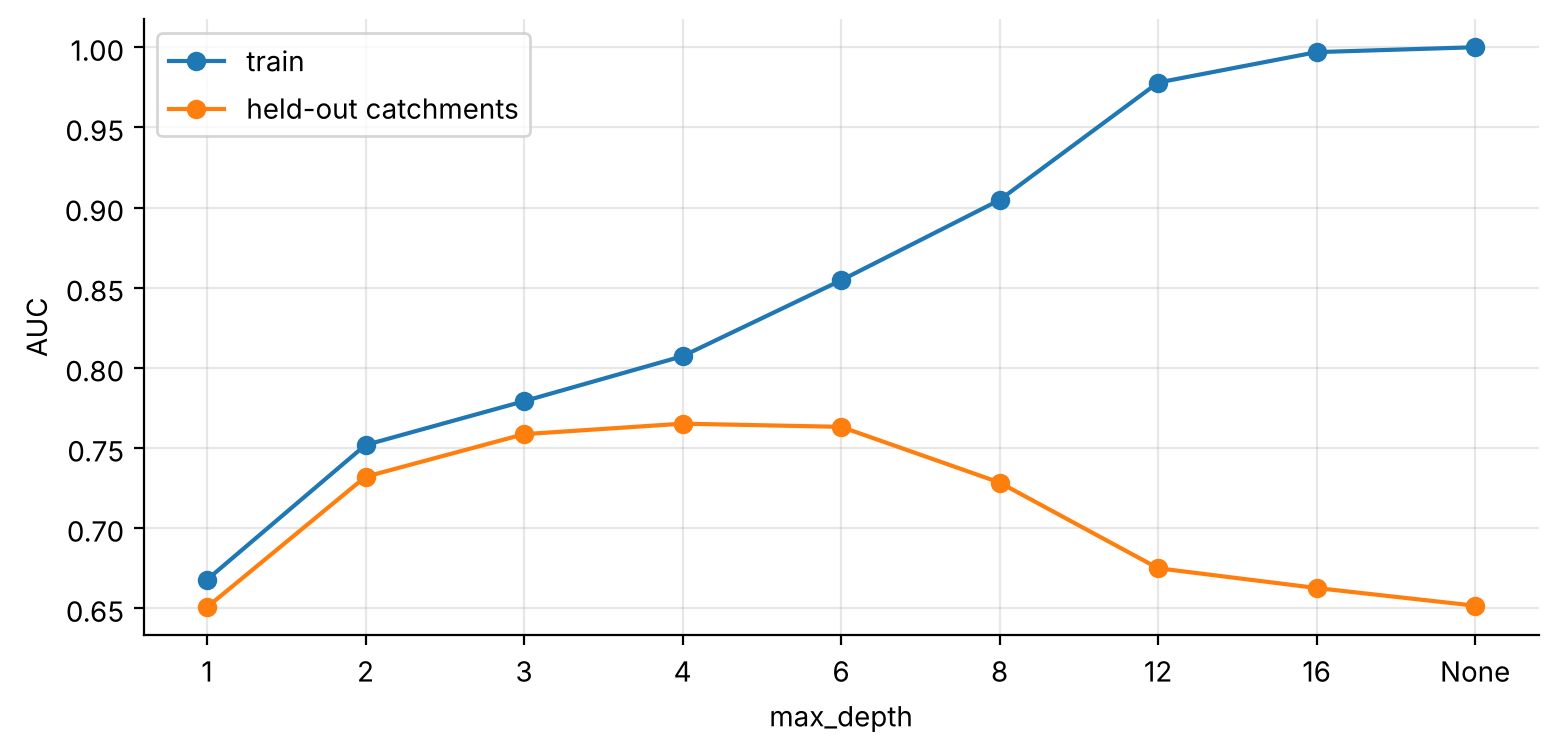

In [5]:
plt.plot(r["max_depth"], r["train AUC"], marker="o", label="train")
plt.plot(r["max_depth"], r["held-out AUC"], marker="o", label="held-out catchments")
plt.xlabel("max_depth"); plt.ylabel("AUC"); plt.legend(); plt.show()

## Cost-complexity (weakest-link) pruning

Grow the full tree $T_0$, then for each $\alpha \ge 0$ find the subtree minimising
$$R_\alpha(T) = R(T) + \alpha\,|T|,$$
where $R(T)$ is the total weighted impurity of the leaves and $|T|$ is the number of leaves. As $\alpha$ rises,
the internal node whose collapse costs least per leaf removed,
$g(t) = \dfrac{R(t) - R(T_t)}{|T_t| - 1}$, goes first. That yields a nested sequence of subtrees, and CV
chooses $\alpha$.

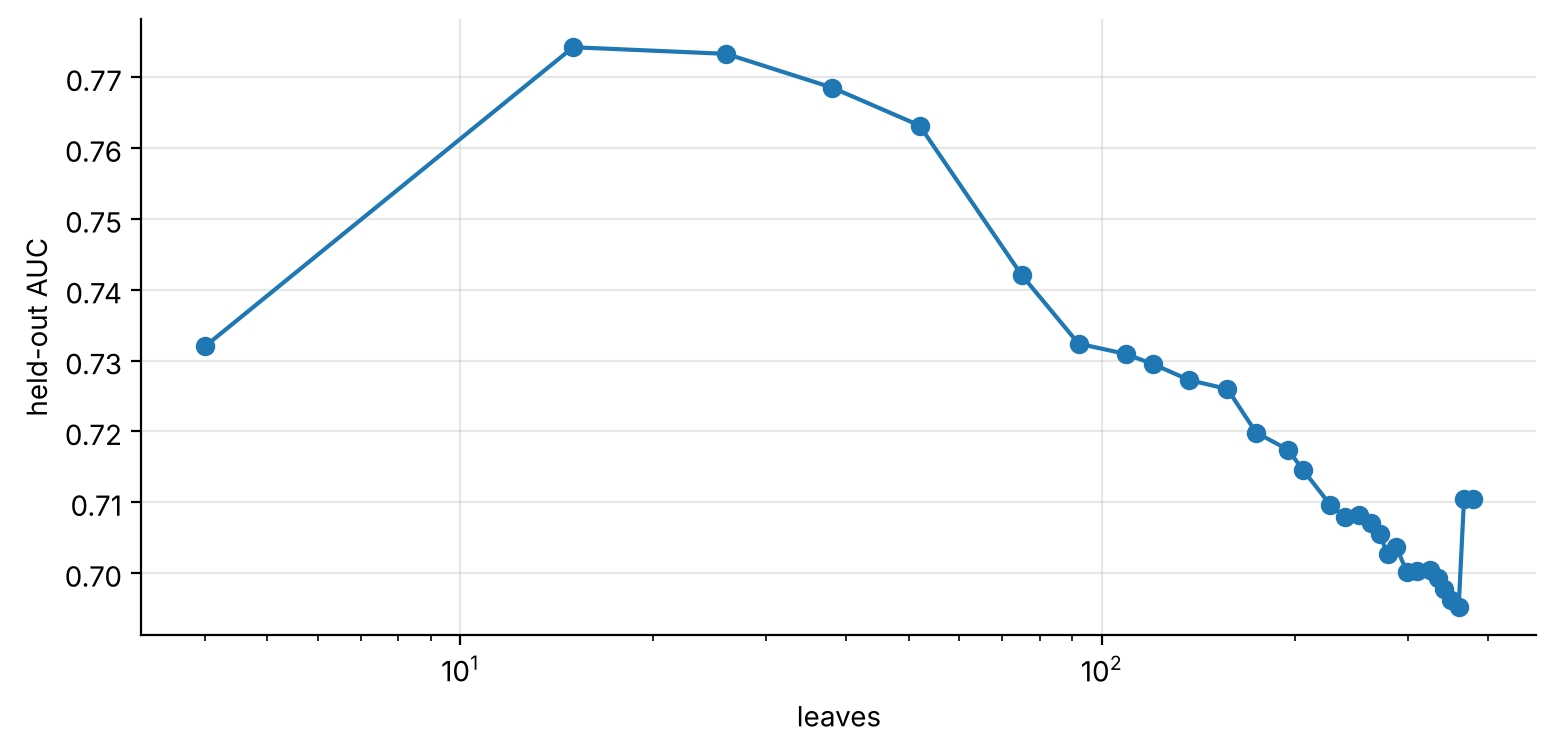

,alpha,leaves,held-out AUC
28,0.00208,15,0.77426
27,0.00138,26,0.77333
26,0.00114,38,0.76856
25,0.00103,52,0.76321
24,0.00090,75,0.74211


In [6]:
full = DecisionTreeClassifier(random_state=0, min_samples_leaf=5)
path = full.cost_complexity_pruning_path(X, y)
alphas = np.unique(np.quantile(path.ccp_alphas, np.linspace(0, 0.99, 30)))
rows = []
for a_ in alphas:
    te = np.zeros(len(y))
    for a, b in folds:
        m = DecisionTreeClassifier(random_state=0, min_samples_leaf=5, ccp_alpha=a_).fit(X[a], y[a])
        te[b] = m.predict_proba(X[b])[:, 1]
    leaves = DecisionTreeClassifier(random_state=0, min_samples_leaf=5, ccp_alpha=a_).fit(X, y).get_n_leaves()
    rows.append((a_, leaves, roc_auc_score(y, te)))
pr = pd.DataFrame(rows, columns=["alpha", "leaves", "held-out AUC"])
plt.plot(pr.leaves, pr["held-out AUC"], marker="o"); plt.xscale("log"); plt.xlabel("leaves"); plt.ylabel("held-out AUC")
plt.show(); pr.sort_values("held-out AUC", ascending=False).head(5).round(5)

**Takeaways**
* Depth, minimum leaf size and $\alpha$ all control the same thing: how finely the tree may carve the data.
* Held-out AUC peaks at depth 4 (0.77) and falls to 0.65 for the fully grown tree, which fits the training
  data perfectly. The best pruned tree has about 15 leaves (AUC 0.77).
* That is still well below an ensemble's 0.81 (notebook 03). Single trees have high **variance**.